In [4]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA = Path('../../../data')
CSV = DATA / 'Transportation_Network_Providers_-_Trips__2018_-_2022_.csv'
EXPORT = Path('../backend/data') 

In [5]:
sample = pd.read_csv(CSV, nrows=100_000)
print(sample.shape)
sample.head(3).T

(100000, 21)


,0,1,2
Trip ID,4577ce90d2adcb90960160973a25d7bc57b54ac9,4577cf00947b51a37ec1337d3ecb7ad02a010426,4577d168ef04a69eab19f2f68eee138eb245a4df
Trip Start Timestamp,01/21/2019 10:30:00 AM,01/03/2019 03:30:00 PM,11/16/2018 11:00:00 PM
Trip End Timestamp,01/21/2019 10:45:00 AM,01/03/2019 04:00:00 PM,11/16/2018 11:15:00 PM
Trip Seconds,561.0,1795.0,1263.0
Trip Miles,1.4,12.1,9.4
Pickup Census Tract,17031081800.0,NaN,NaN
Dropoff Census Tract,17031280100.0,17031081202.0,NaN
Pickup Community Area,8.0,NaN,28.0
Dropoff Community Area,28.0,8.0,42.0
Fare,5.0,20.0,10.0


In [6]:
missing = (sample.isna().mean() * 100).round(1)
missing[missing > 0].to_frame('% missing').T

,Pickup Census Tract,Dropoff Census Tract,Pickup Community Area,Dropoff Community Area,Pickup Centroid Latitude,Pickup Centroid Longitude,Pickup Centroid Location,Dropoff Centroid Latitude,Dropoff Centroid Longitude,Dropoff Centroid Location
% missing,28.5,28.9,5.7,6.4,5.6,5.6,5.6,6.3,6.3,6.3


In [7]:
starts = pd.to_datetime(sample['Trip Start Timestamp'], format='%m/%d/%Y %I:%M:%S %p')
print('earliest and latest start in the sample:', starts.min(), '/', starts.max())
print('distinct minute values:', sorted(int(m) for m in starts.dt.minute.unique()))
print('is the sample sorted by start time:', starts.is_monotonic_increasing)
print('years represented:', sorted(int(y) for y in starts.dt.year.unique()))

earliest and latest start in the sample: 2018-11-01 00:00:00 / 2022-08-28 22:30:00
distinct minute values: [0, 15, 30, 45]
is the sample sorted by start time: False
years represented: [2018, 2019, 2020, 2022]


In [9]:
raw = pd.read_csv(
    CSV,
    usecols=['Trip Start Timestamp', 'Pickup Community Area'],
    on_bad_lines='skip',
    low_memory=False,
)
raw.columns = ['start', 'pickup_area']
raw['start'] = pd.to_datetime(raw['start'], format='%m/%d/%Y %I:%M:%S %p', errors='coerce')

raw.tail(6)

,start,pickup_area
4811240,2019-02-07 18:45:00,32.0
4811241,2018-12-19 16:15:00,NaN
4811242,NaT,NaN
4811243,NaT,NaN
4811244,NaT,NaN
4811245,NaT,NaN


In [10]:
with open(CSV, 'rb') as f:
    f.seek(-350, 2)
    print(f.read().decode())

7/2019 07:00:00 PM,935,2.8,17031839100,17031832600,32,7,15,0,2.85,17.85,false,1,41.8809944707,-87.6327464887,POINT (-87.6327464887 41.8809944707),41.9147473049,-87.6540070286,POINT (-87.6540070286 41.9147473049)
69bbe967dc87186edc1e580a49bcd8795f44939a,12/19/2018 04:15:00 PM,12/{
  "error" : true,
  "message" : "Internal error",
  "status" : 500
}



**Observation:** the last 4 rows has invalid data, looks like error response from API

In [11]:
trips = raw.dropna(subset=['start'])
del raw
print(f'{len(trips):,} trips with a valid start time, {trips.memory_usage(deep=True).sum() / 1e6:,.0f} MB')

4,811,242 trips with a valid start time, 77 MB


first trip: 2018-11-01 00:00:00  last trip: 2022-08-31 19:00:00


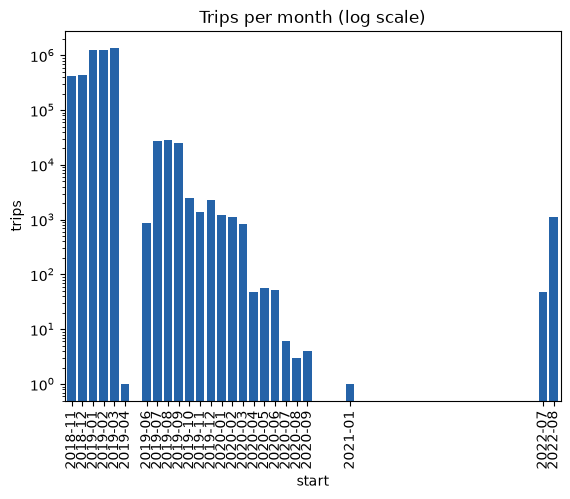

In [12]:
print('first trip:', trips['start'].min(), ' last trip:', trips['start'].max())

monthly = trips['start'].dt.to_period('M').value_counts().sort_index()
ax = monthly.plot.bar(logy=True, color='#2563a8', width=0.8)
ax.set_title('Trips per month (log scale)')
ax.set_ylabel('trips')
plt.show()

In [13]:
monthly.to_frame('trips').T

start,2018-11,2018-12,2019-01,2019-02,2019-03,2019-04,2019-06,2019-07,2019-08,2019-09,...,2020-03,2020-04,2020-05,2020-06,2020-07,2020-08,2020-09,2021-01,2022-07,2022-08
trips,427265,433541,1245094,1251736,1360128,1,857,27814,28900,25310,...,823,48,57,52,6,3,4,1,47,1102


In [14]:
daily = trips.set_index('start').resample('D').size()
daily['2019-03-24':'2019-04-02'].to_frame('trips').T

start,2019-03-24,2019-03-25,2019-03-26,2019-03-27,2019-03-28,2019-03-29,2019-03-30,2019-03-31,2019-04-01,2019-04-02
trips,40658,36211,36899,38301,41408,51826,393,863,0,0


**Observations**

- Full days up to 29 March, then a few hundred trips on the 30th and 31st, and a single trip in April.

In [15]:
WINDOW_START, WINDOW_END = pd.Timestamp('2019-01-01'), pd.Timestamp('2019-03-30')   # end is exclusive
win = trips[(trips['start'] >= WINDOW_START) & (trips['start'] < WINDOW_END)]
print(f'{len(win):,} trips in the window')

3,855,702 trips in the window


## 1.4 Data quality inside the window

In [16]:
print('minute values:', sorted(int(m) for m in win['start'].dt.minute.unique()),
      ' second values:', sorted(int(s) for s in win['start'].dt.second.unique()))
print(f"pickup area missing: {win['pickup_area'].isna().mean():.1%}")

minute values: [0, 15, 30, 45]  second values: [0]
pickup area missing: 5.8%


**Observations**

- The usable data is **1 Jan - 29 Mar 2019**, with a start time (rounded to 15 min) and, for ~94% of trips

In [20]:
import requests

# The CSV only has area numbers. The names come from the city's community-areas dataset on the same portal.
resp = requests.get('https://data.cityofchicago.org/resource/igwz-8jzy.json',
                    params={'$select': 'area_numbe,community', '$limit': 100}, timeout=30)
resp.raise_for_status()
area_names = {int(r['area_numbe']): r['community'].title() for r in resp.json()}


print(f'{len(area_names)} community areas, e.g.', list(area_names.items())[:3])

77 community areas, e.g. [(1, 'Rogers Park'), (2, 'West Ridge'), (3, 'Uptown')]


3,631,596 trips with a pickup area (5.8% dropped)


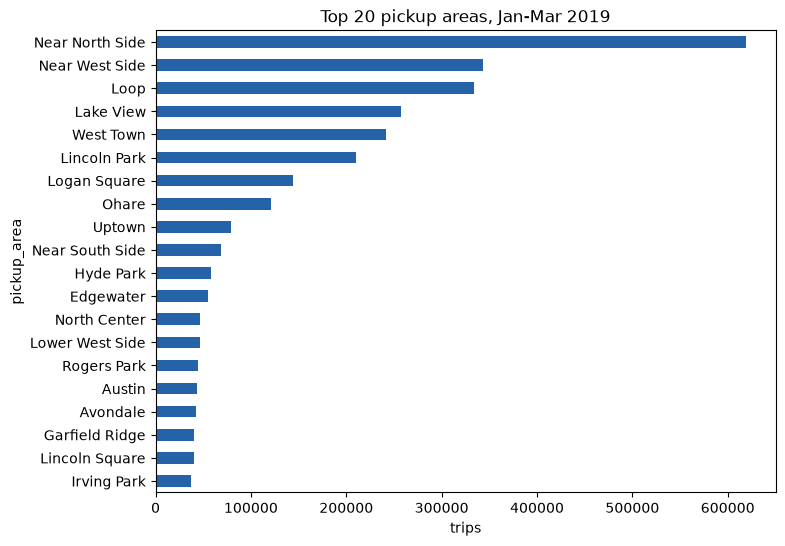

In [21]:
in_city = win.dropna(subset=['pickup_area']).copy()
in_city['pickup_area'] = in_city['pickup_area'].astype(int)
print(f'{len(in_city):,} trips with a pickup area ({1 - len(in_city) / len(win):.1%} dropped)')

by_area = in_city['pickup_area'].map(area_names).value_counts()
ax = by_area.head(20)[::-1].plot.barh(color='#2563a8', figsize=(8, 6))
ax.set_title('Top 20 pickup areas, Jan-Mar 2019')
ax.set_xlabel('trips')
plt.show()

In [22]:
share = by_area / by_area.sum()
print(f'top 3 areas: {share.head(3).sum():.0%} of trips')
print(f'areas with under 5,000 trips in three months: {(by_area < 5000).sum()} of {len(by_area)}')
by_area.tail(5).to_frame('trips')

top 3 areas: 36% of trips
areas with under 5,000 trips in three months: 12 of 77


,trips
pickup_area,
Mount Greenwood,3088
Riverdale,2407
East Side,1699
Burnside,1478
Hegewisch,1195


In [23]:
in_city['hour_start'] = in_city['start'].dt.floor('h')
hourly = in_city.groupby(['pickup_area', 'hour_start']).size().rename('trips')
print(f'{len(hourly):,} area-hours have at least one trip')

149,506 area-hours have at least one trip


A count table only has rows for hours *with* trips. The missing rows are hours with **zero** trips. To know how many there are, build the full calendar of hours.

In [28]:
# "A count table only has rows for hours *with* trips" (previous cell) - so
# build the full calendar of hours in the window and see which ones never
# got a row at all, in ANY area.
calendar = pd.date_range(WINDOW_START, WINDOW_END, freq='h', inclusive='left')
print(f'{len(calendar):,} possible hours in the window')

present_hours = set(hourly.index.get_level_values('hour_start'))
missing_everywhere = [h for h in calendar if h not in present_hours]
print('hour(s) missing from every single area:', [str(h) for h in missing_everywhere])

missing_hour = missing_everywhere[0]
try:
    missing_hour.tz_localize('America/Chicago')
    print(f'{missing_hour} is a valid America/Chicago local time')
except Exception as e:
    print(f'{missing_hour} is NOT a valid America/Chicago local time: {e}')

2,112 possible hours in the window
hour(s) missing from every single area: ['2019-03-10 02:00:00']
2019-03-10 02:00:00 is NOT a valid America/Chicago local time: 2019-03-10 02:00:00 is a nonexistent time due to daylight savings time. Try using the 'nonexistent' argument.


In [29]:
day_names = calendar.normalize().unique().day_name()
pd.Series(day_names).value_counts()

Tuesday      13
Wednesday    13
Thursday     13
Friday       13
Saturday     12
Sunday       12
Monday       12
Name: count, dtype: int64

In [30]:
total_per_area = hourly.groupby(level='pickup_area').sum()
rows_per_area = hourly.groupby(level='pickup_area').size()
coverage = rows_per_area / len(calendar)

comparison = pd.DataFrame({
    'coverage': coverage,
    'naive_avg_trips_per_hr': total_per_area / rows_per_area,
    'zero_filled_avg_trips_per_hr': total_per_area / len(calendar),
}).rename(index=area_names).sort_values('coverage')

comparison.head(6).round(2)

,coverage,naive_avg_trips_per_hr,zero_filled_avg_trips_per_hr
pickup_area,,,
Hegewisch,0.40,1.41,0.57
Burnside,0.46,1.51,0.70
East Side,0.52,1.53,0.80
Riverdale,0.63,1.81,1.14
Mount Greenwood,0.65,2.24,1.46
Edison Park,0.67,2.46,1.64


**Observations**

- Exactly one hour in the window never happened at all: **2019-03-10 02:00**, Chicago's spring-forward DST change (confirmed above - pandas itself refuses to localize that local time). It's missing from *every* area, not just quiet ones, so it isn't a zero-trip hour, it's not an hour at all. Any per-slot average has to exclude it from the denominator instead of counting it as a zero.
- The 88-day window doesn't split evenly into weeks: Tuesday-Friday occur 13 times each, Monday/Saturday/Sunday only 12. A single "divide by number of weeks" constant would be wrong for 3 of the 7 weekdays - the denominator has to be computed per hour-of-week, not assumed constant.
- Hour-coverage (rows present / 2,112 possible hours) ranges from 100% (Loop, Near West Side, ...) down to 40% for Hegewisch. For a low-volume area, averaging over existing rows only overstates demand by roughly 2.5x (Hegewisch: naive 1.41 trips/hr vs zero-filled 0.57 trips/hr). This is exactly the bug zero-filling exists to prevent, and it is worst for the areas an operator would most need a trustworthy number for.

Recommendation API's baseline calculation: divide by the number of hours that actually occurred for that hour-of-week (not the row count, not a flat constant), and explicitly skip the one hour that structurally cannot occur.

**Export the two tables**

 `community_areas.csv` and `trip_hourly.csv`

In [27]:
EXPORT.mkdir(parents=True, exist_ok=True)

areas_df = pd.DataFrame({'id': list(area_names), 'name': list(area_names.values())})
areas_df.to_csv(EXPORT / 'community_areas.csv', index=False)

trip_hourly = (hourly.reset_index()
               .rename(columns={'pickup_area': 'area_id'})
               .assign(hour_start=lambda d: d['hour_start'].dt.strftime('%Y-%m-%d %H:00'))
               .sort_values(['area_id', 'hour_start'])
               .reset_index(drop=True))
trip_hourly.to_csv(EXPORT / 'trip_hourly.csv', index=False)

for name in ['community_areas.csv', 'trip_hourly.csv']:
    p = EXPORT / name
    print(f'{p}  {p.stat().st_size / 1e6:.2f} MB')
trip_hourly.head()

../backend/data/community_areas.csv  0.00 MB
../backend/data/trip_hourly.csv  3.34 MB


,area_id,hour_start,trips
0,1,2019-01-01 00:00,34
1,1,2019-01-01 01:00,51
2,1,2019-01-01 02:00,68
3,1,2019-01-01 03:00,29
4,1,2019-01-01 04:00,30
